In [ ]:
import pandas as pd
from google.colab import files
uploaded=files.upload()

Saving profit_analysis_startup.csv to profit_analysis_startup.csv


In [ ]:
df=pd.read_csv(next(iter(uploaded)))
df.head()

,RD_Spend,Administration,Marketing_Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RD_Spend         50 non-null     float64
 1   Administration   50 non-null     float64
 2   Marketing_Spend  50 non-null     float64
 3   State            50 non-null     object 
 4   Profit           50 non-null     float64
dtypes: float64(4), object(1)
memory usage: 2.1+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,RD_Spend,Administration,Marketing_Spend,Profit
count,50.000000,50.000000,50.000000,50.000000
mean,73721.615600,121344.639600,211025.097800,112012.639200
std,45902.256482,28017.802755,122290.310726,40306.180338
min,0.000000,51283.140000,0.000000,14681.400000
25%,39936.370000,103730.875000,129300.132500,90138.902500
50%,73051.080000,122699.795000,212716.240000,107978.190000
75%,101602.800000,144842.180000,299469.085000,139765.977500
max,165349.200000,182645.560000,471784.100000,192261.830000


In [ ]:
df['State'].value_counts()

,count
State,
New York,17
California,17
Florida,16


In [ ]:
df.groupby('State')['Profit'].mean()

,Profit
State,
California,103905.175294
Florida,118774.024375
New York,113756.446471


In [ ]:
df.groupby('State')['Profit'].sum()

,Profit
State,
California,1766387.98
Florida,1900384.39
New York,1933859.59


In [ ]:
df.groupby('State')['Profit'].agg(['count','mean','sum'])

,count,mean,sum
State,,,
California,17,103905.175294,1766387.98
Florida,16,118774.024375,1900384.39
New York,17,113756.446471,1933859.59


In [ ]:
df.loc[df['Profit'].idxmax()]

,0
RD_Spend,165349.2
Administration,136897.8
Marketing_Spend,471784.1
State,New York
Profit,192261.83


In [ ]:
df.loc[df['Profit'].idxmin()]

,49
RD_Spend,0.0
Administration,116983.8
Marketing_Spend,45173.06
State,California
Profit,14681.4


In [ ]:
df[['RD_Spend','Administration','Marketing_Spend','Profit']].corr()

,RD_Spend,Administration,Marketing_Spend,Profit
RD_Spend,1.000000,0.241955,0.724248,0.972900
Administration,0.241955,1.000000,-0.032154,0.200717
Marketing_Spend,0.724248,-0.032154,1.000000,0.747766
Profit,0.972900,0.200717,0.747766,1.000000


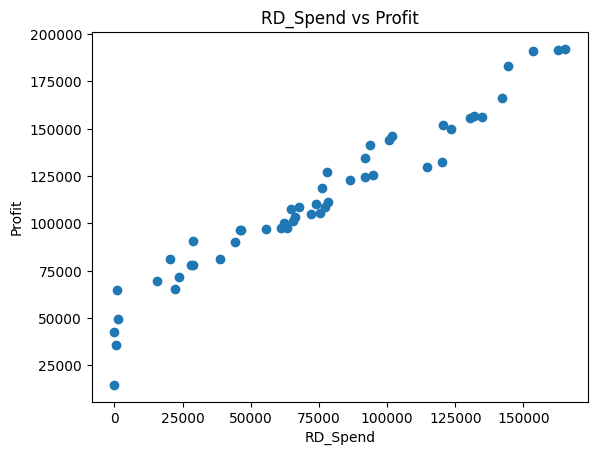

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df['RD_Spend'],df['Profit'])
plt.xlabel('RD_Spend')
plt.ylabel('Profit')
plt.title('RD_Spend vs Profit')
plt.show()

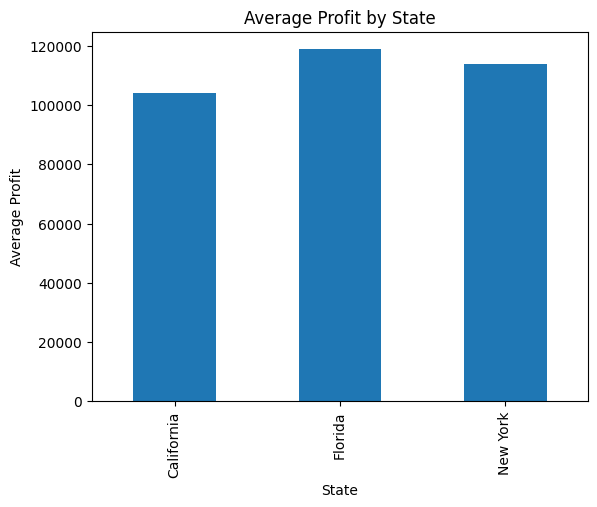

In [ ]:
df.groupby('State')['Profit'].mean().plot(kind='bar')
plt.xlabel('State')
plt.ylabel('Average Profit')
plt.title('Average Profit by State')
plt.show()

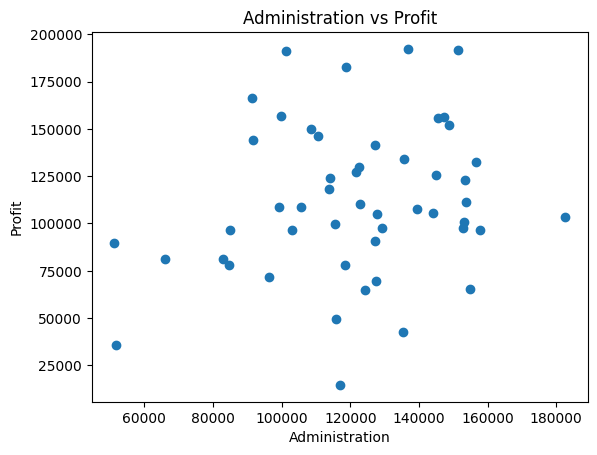

In [ ]:
plt.scatter(df['Administration'],df['Profit'])
plt.xlabel('Administration')
plt.ylabel('Profit')
plt.title('Administration vs Profit')
plt.show()

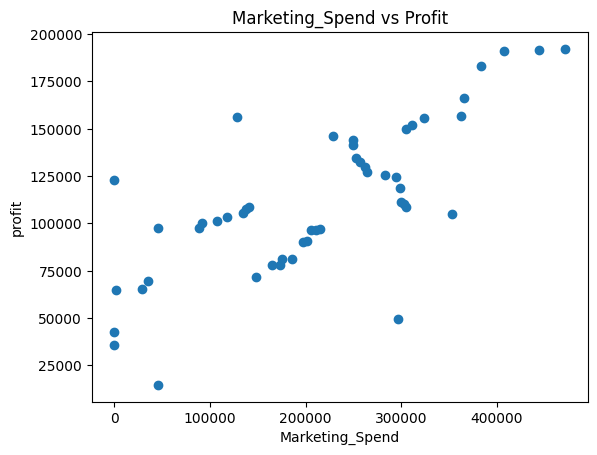

In [ ]:
plt.scatter(df['Marketing_Spend'],df['Profit'])
plt.xlabel('Marketing_Spend')
plt.ylabel('profit')
plt.title('Marketing_Spend vs Profit')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
X=df[['RD_Spend','Administration','Marketing_Spend']]
y=df['Profit']
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)
model=LinearRegression()
model.fit(X_train,y_train)


LinearRegression()

In [ ]:
from sklearn.metrics import r2_score
y_pred=model.predict(X_test)

In [ ]:
print('R2 Score:',r2_score(y_test,y_pred))
print('Coefficients:',model.coef_)
print('Intercept:',model.intercept_)

R2 Score: 0.9000653083037321
Coefficients: [ 0.80377928 -0.06792917  0.03124155]
Intercept: 54071.87574599082


In [ ]:
import numpy as np
new_data=np.array([
    [21892.92,81910.77,164270.7],
    [23940.93,96489.63,137001.1]
])
predicted_profit=model.predict(new_data)
print('Predicted_Profits:',predicted_profit)

Predicted_Profits: [71236.89079079 71040.76440737]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
